# 03.6 · 因子挖掘进阶：遗传规划 · 强化学习 · 深度学习 · LLM

> 手工因子依赖研究员的经验和灵感，覆盖面有限。**自动因子挖掘**让算法在巨大的公式/特征空间里自动搜索有效因子，是近年来量化研究的前沿。
> 本节你将了解因子挖掘的完整技术谱系，并**亲手跑一个遗传规划（GP）自动发现因子**。

## 一、因子挖掘的技术演进

| 阶段 | 代表方法 | 特点 |
|---|---|---|
| 手工因子 | 反转、价值、质量 | 可解释、依赖经验 |
| 公式因子库 | WorldQuant Alpha101、Alpha191 | 人工总结的上百个公式 |
| **遗传规划** | gplearn、gplearn-based | 符号回归，自动组合算子与因子 |
| **强化学习** | AlphaGen（KDD 2023） | RL 智能体生成表达式，奖励=IC/夏普 |
| **深度学习** | LSTM/Transformer/AE/GNN | 自动学习非线性因子表示 |
| **LLM 多智能体** | 微软 RD-Agent | 大模型自动提假设、写代码、回测、迭代 |

共同目标：**在巨大的搜索空间里，自动找到样本外仍有效的因子**。

## 二、遗传规划（Genetic Programming）原理

遗传规划借鉴生物进化，把因子表示为一棵**表达式树**：

- **叶子节点（terminals）**：基础因子（如 ret5、ret20、波动率、市值）和常数；
- **内部节点（functions）**：算子（截面 rank、时序均值/标准差、加减乘、延迟等）；
- 每棵树就是一个因子公式。

进化流程（**核心循环**）：
1. **初始化**：随机生成一批表达式树（种群）；
2. **评估适应度**：用因子的 IC（或 IR、夏普）给每个因子打分；
3. **选择**：保留适应度高的个体（精英）；
4. **交叉（crossover）**：两个父代交换子树，产生后代；
5. **变异（mutation）**：随机替换某个子树；
6. 重复 2–5，种群逐代进化，直到收敛。

## 三、动手：用遗传规划自动挖因子（代码在 factor_lab.mining）

In [1]:
import sys, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.mining import make_base, run_gp, expr_to_str
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
base = make_base(close, F['$volume'].unstack('instrument'),
                 F['$mkt_cap_ard'].unstack('instrument'),
                 F['$pe_ttm'].unstack('instrument'),
                 F['$pb_lf'].unstack('instrument'))
# 用 5 日未来收益作为预测目标；采样间隔 5 天，避免重叠
fwd5 = close.shift(-5)/close - 1
print('准备就绪，开始进化（60 个体 × 10 代）...')

[20236:MainThread](2026-10-30 01:09:22,445) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[20236:MainThread](2026-10-30 01:09:23,915) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[20236:MainThread](2026-10-30 01:09:23,916) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


准备就绪，开始进化（60 个体 × 10 代）...


In [2]:
t0 = time.time()
scored, hist = run_gp(base, fwd5, n_pop=60, n_gen=10, n_elite=8,
                      sample_step=5, seed=7, verbose=True)
print('进化完成，耗时 %.1f 秒' % (time.time()-t0))

第0代 最优|IC|=0.0240


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


第1代 最优|IC|=0.0253


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


... (10 outputs left out)

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


第7代 最优|IC|=0.0280


第8代 最优|IC|=0.0280


第9代 最优|IC|=0.0280
进化完成，耗时 157.5 秒


画出**进化曲线**——种群的最优适应度随代数提升，然后收敛：

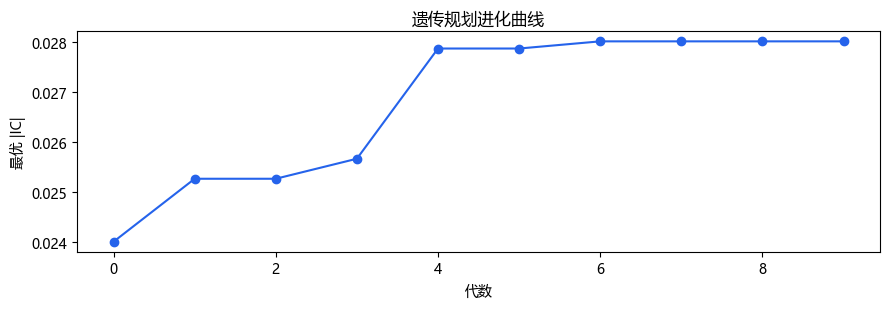

进化前后最优 |IC|: 0.0240 -> 0.0280

自动发现的 Top 5 因子公式：
|IC|=0.0280  ts_max10(ts_mean10(ts_max10(ts_max10(ret20))))
|IC|=0.0279  ts_max10(ts_max10(ts_mean10(ts_max10(ret20))))
|IC|=0.0279  ts_mean10(ts_max10(ts_max10(ts_max10(ret20))))
|IC|=0.0279  ts_mean10(ts_max10(ts_max10(ts_max10(ret20))))
|IC|=0.0277  ts_max10(ts_max10(ts_max10(ts_max10(ret5))))


In [3]:
plt.figure(figsize=(9, 3.2))
plt.plot(range(len(hist)), hist, marker='o', color='#2563eb')
plt.xlabel('代数'); plt.ylabel('最优 |IC|'); plt.title('遗传规划进化曲线')
plt.tight_layout(); plt.show()

print('进化前后最优 |IC|: %.4f -> %.4f' % (hist[0], hist[-1]))
print('\n自动发现的 Top 5 因子公式：')
for a, m, e in scored[:5]:
    print('|IC|=%.4f  %s' % (a, expr_to_str(e)))

**如何解读？**
- 算法在没有人工干预的情况下，自动组合算子，发现了一批因子，最优样本内 IC 约 0.028；
- 进化曲线显示适应度逐步提升后收敛，说明搜索在起作用；
- 但在沪深300、有限算子/代数下，自动因子与手工因子水平相当——**要获得更强因子，需要更大的股票池、更丰富的算子、更长的进化和更多算力**，同时必须严格做样本外验证。

## 四、gplearn：工业级遗传规划

我们手写的是教学版。工程上常用 **gplearn**（`pip install gplearn`），它支持自定义算子、并行、适应度函数（可直接把"因子 IC"作为 fitness）。

```python
from gplearn import SymbolicTransformer
# function_set 可加入自定义的截面/时序算子，metric 用因子 IC
st = SymbolicTransformer(function_set=['add','sub','mul', ts_rank, cs_rank],
                         generations=20, population_size=1000,
                         metric=factor_ic, n_jobs=-1)
st.fit(X_fundamental, y_forward_return)
```

> 注意：gplearn 默认面向表格回归，**做截面因子需要自定义时序算子和滚动 IC 适应度**，并按交易日滚动（防止前视）。

## 五、强化学习因子：AlphaGen

**AlphaGen（KDD 2023）** 把因子挖掘建模为**强化学习**：
- **智能体（agent）**：逐步"生成"表达式（每一步选择一个算子或因子，相当于在表达式树上生长）；
- **动作（action）**：选择算子（rank、ts_mean、corr…）或基础因子；
- **奖励（reward）**：生成因子的 IC、IR 或分层多空收益；
- 智能体通过策略梯度（如 PPO）学习"如何构造高奖励因子"。

相比 GP 的随机变异，RL 有**策略性地**搜索，常能找到更稳定的因子。AlphaGen 同样基于 Qlib 数据。

## 六、深度学习因子

不依赖显式公式，直接用神经网络学习因子表示：
- **LSTM / GRU / Transformer**：输入一段时间的量价序列，输出未来收益预测（黑盒 alpha）；
- **自动编码器（Autoencoder）**：学习截面收益的隐含因子结构；
- **图神经网络（GNN）**：把股票关系（供应链、同行业）建成图，学习关系因子；
- **因子蒸馏**：把深度因子的预测蒸馏成可解释的线性因子。

优点：能捕捉非线性、交互；缺点：可解释性弱、易过拟合、对数据和算力要求高。

## 七、LLM 因子挖掘：RD-Agent

微软 **RD-Agent** 用大模型形成自动化研究闭环：
1. **提出假设**：LLM 基于文献/历史提出新因子想法；
2. **写代码**：自动生成因子计算与回测代码（在 Docker 中安全执行）；
3. **评估反馈**：读取 IC、回测结果，LLM 分析成败；
4. **迭代**：根据反馈改进因子，循环往复。

需要 LLM API 与 Docker 环境。它把"研究员的思考过程"自动化，是最前沿的方向。

## 八、自动因子挖掘的陷阱（务必警惕）

自动搜索空间巨大，**最大的风险是过拟合和虚假因子**：
- **数据挖掘偏差 / 多重检验**：试了成千上万个因子，总有几个样本内"看起来好"（纯属偶然）；
- **样本外衰减**：样本内 IC 高、样本外失效；
- **前视偏差**：误用未来数据（如用了未来才能知道的成分、财务数据）；
- **无法交易**：忽略停牌、涨跌停、容量、冲击成本。

**规范做法：**
1. 严格划分训练 / 验证 / 样本外（甚至滚动样本外）；
2. 控制搜索次数，做**多重检验校正**（如 Bonferroni、Deflated Sharpe）；
3. 因子必须在**样本外、不同股票池、不同时间段**仍有效；
4. 结合交易成本与容量评估；
5. 对自动因子做经济学/行为学解释，避免纯数据拟合。

## 九、小结与面试要点

- 因子挖掘谱系：**公式库 → 遗传规划（gplearn）→ 强化学习（AlphaGen）→ 深度学习 → LLM（RD-Agent）**。
- GP 核心：表达式树 + 适应度（IC）+ 选择/交叉/变异，种群逐代进化（我们实测 |IC| 0.024→0.028）。
- 自动因子必须过**样本外、多重检验、交易成本**三关，否则是过拟合。

**面试高频：**
- 遗传规划挖因子的原理？怎么避免过拟合？（答：表达式树进化；样本外+多重检验+控制搜索次数）
- AlphaGen 和 gplearn 的区别？（答：AlphaGen 用 RL 策略性搜索，GP 靠随机变异）
- 你试了 1000 个因子找到 10 个有效，能直接用吗？（答：不能，需多重检验校正和样本外验证，否则是数据挖掘偏差）
- 深度学习因子的优劣？（答：非线性强但可解释性弱、易过拟合）

## 动手练习
1. 改变 GP 的算子集合和代数，观察最优因子变化；
2. 把最优因子拿到样本外（最后一年）重新评估 IC；
3. 思考：为什么因子的样本外 IC 通常远低于样本内？

---
模块 3「因子研究」完成。进入 **模块 4：模型预测（线性 → LightGBM → 深度学习，多因子合成与收益预测）**。